In [ ]:
!pip install yfinance

/tmp/ipykernel_518/1527474309.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download('^NSEI' , '2023-01-01' , date.today())
[*********************100%***********************]  1 of 1 completed


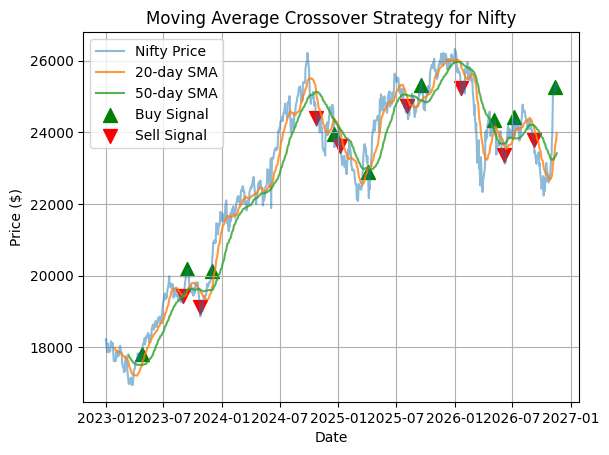

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import date
import yfinance as yf

df = yf.download('^NSEI' , '2023-01-01' , date.today())
df = df.dropna()

df['SMA20'] = df['Close'].rolling(window = 20).mean()
df['SMA50'] = df['Close'].rolling(window = 50).mean()

df['Signal'] = np.where(df['SMA20'] > df['SMA50'],1 , 0)

df['Position'] = df['Signal'].diff()

plt.figure(figsize=(12,8))

plt.plot(df.index, df['Close'], label='Nifty Price', alpha=0.5)
plt.plot(df.index, df['SMA20'], label='20-day SMA', alpha=0.8)
plt.plot(df.index, df['SMA50'], label='50-day SMA', alpha=0.8)

buy_signals = df[df['Position'] == 1].index
sell_signals = df[df['Position'] == -1].index

plt.scatter(buy_signals, df.loc[buy_signals, 'Close'],
            marker='^', color='green', s=100, label='Buy Signal')
plt.scatter(sell_signals, df.loc[sell_signals, 'Close'],
            marker='v', color='red', s=100, label='Sell Signal')


plt.title('Moving Average Crossover Strategy for Nifty')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.legend()
plt.grid(True)
plt.show()